# Step 3 — Model Extensions

The Step 2 configuration (`STEP2_CONFIG`: word 1–2 grams + `char_wb` 3–5 grams TF-IDF, structured features, class-weighted `LinearSVC`) is the baseline. It was confirmed on fresh folds in `robustness_checks.ipynb`. All runs use the Step 1 protocol on the **original folds (seed 0)**, so the results are paired with the saved Step 1 and Step 2 fold results. The test set is not used.

### Candidates and decision rules (fixed before running)

| # | Candidate | What it adds | Decision |
|---|---|---|---|
| 1 | **Calibration** | Maps SVM scores to probabilities. Platt (sigmoid) and isotonic calibrators are fitted on the inner out-of-fold scores of each training fold. | A monotone map does not change ranking, so PR-AUC and F1 are not affected. Judged by Brier score and expected calibration error (ECE). Platt is the default; isotonic is chosen only if its Brier score is lower in ≥ 12/15 folds. |
| 2 | **Sentence embeddings** | 384-dimensional `all-MiniLM-L6-v2` vectors of title + description appended to the Step 2 features. | PR-AUC rule against the baseline: positive mean paired gain and better in ≥ 12/15 folds. |
| 3 | **LightGBM stacking** | A gradient boosting model on the out-of-fold Step 2 SVM score plus structured features (binary flags, lengths, empty-field flags, contact-token counts, five categorical fields; no location). | Same PR-AUC rule. |

If both 2 and 3 pass, one combination is run (stacking on top of the SVM with embeddings) and kept only if it passes the rule against the better of the two. No other variants are added after seeing results, and the LightGBM settings below are fixed (not tuned).

In [1]:
import sklearn

if sklearn.__version__ != "1.6.1":
    raise RuntimeError(
        f"This notebook uses scikit-learn 1.6.1 (found {sklearn.__version__}). "
        "Install the pinned versions with: pip install -r requirements.txt"
    )

import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier

from fakejob.data import load_split
from fakejob.embeddings import EMBEDDING_MODEL, MAX_SEQ_LENGTH, posting_embeddings
from fakejob.evaluation import compare, passes_rule, repeated_group_cv
from fakejob.features import (
    BASE_BINARY, BASE_CATEGORICAL, EXTRA_BINARY, EXTRA_CATEGORICAL, META_COLUMNS,
    STEP2_CONFIG, build_pipeline, posting_features,
)
from fakejob.models import GroupedStacking

pd.set_option("display.precision", 3)
RESULTS_DIR = Path("results")
METRICS = ["average_precision", "roc_auc", "f1", "precision", "recall"]

## Data

The sentence embeddings come from a pre-trained model used without fine-tuning: each vector depends only on its own posting, so computing them once for all postings does not leak information. They are cached in `cache/` (not tracked by git; the first run takes about 20 minutes on a CPU). The group labels are added as a column for the stacking model's inner CV; no model uses them as a feature.

In [2]:
split = load_split()
start = time.time()
embeddings = posting_embeddings(split.model_df)
print(f"Embeddings: {embeddings.shape} from {EMBEDDING_MODEL} (max {MAX_SEQ_LENGTH} word pieces), {time.time() - start:.0f}s")

features = pd.concat([posting_features(split.model_df), embeddings], axis=1).assign(group=split.groups)

dev_index = split.dev_index
X_dev = features.loc[dev_index]
y_dev = split.y.loc[dev_index]
groups_dev = split.groups.loc[dev_index]
print(f"Development data: {len(dev_index)} postings, {int(y_dev.sum())} fake")

Embeddings: (17598, 384) from sentence-transformers/all-MiniLM-L6-v2 (max 256 word pieces), 0s


Development data: 15001 postings, 724 fake


## Helper

Same `run()` and `judge()` as in Step 2. All candidates here use the character n-gram TF-IDF, so four parallel workers are used to limit memory.

In [3]:
results = {}

def run(name, estimator, **kwargs):
    start = time.time()
    result = repeated_group_cv(
        estimator, X_dev, y_dev, groups_dev, name=name,
        n_splits=5, n_repeats=3, inner_splits=3, seed=0, n_jobs=4, **kwargs,
    )
    results[name] = result
    result.folds.to_csv(RESULTS_DIR / f"step3_{name}_folds.csv", index=False)
    print(f"{name}: {time.time() - start:.0f}s")
    return result

def judge(reference, candidates):
    rows = []
    for cand in candidates:
        comparison = compare(reference, cand, metrics=METRICS)
        ap, f1 = comparison.loc["average_precision"], comparison.loc["f1"]
        rows.append({
            "variant": cand.name,
            "PR-AUC": f"{cand.folds['average_precision'].mean():.3f} ± {cand.folds['average_precision'].std():.3f}",
            "Δ PR-AUC": ap["mean_diff"],
            "PR-AUC wins": ap["folds_improved"],
            "F1": f"{cand.folds['f1'].mean():.3f} ± {cand.folds['f1'].std():.3f}",
            "Δ F1": f1["mean_diff"],
            "F1 wins": f1["folds_improved"],
            "Δ recall": comparison.loc["recall", "mean_diff"],
            "passes rule": passes_rule(comparison),
        })
    return pd.DataFrame(rows).set_index("variant")

## Baseline and Candidate 1: Calibration

The Step 2 configuration is re-run with `calibrate=True`. The assertion checks that its ranking and threshold metrics are identical to the saved Step 2 results, so the calibration metrics belong to exactly the same model.

- **Brier score**: mean squared difference between the predicted probability and the label (lower is better). `brier_prior` predicts the training fake rate for every posting and is the reference a useful model must beat.
- **ECE** (expected calibration error): postings are binned by predicted probability (10 equal-width bins); ECE is the weighted mean gap between the predicted probability and the observed fake rate in each bin.

In [4]:
baseline = run("step2_baseline", build_pipeline(STEP2_CONFIG), calibrate=True)

saved_step2 = pd.read_csv(RESULTS_DIR / "step2_combined_folds.csv")
assert np.allclose(baseline.folds[METRICS].values, saved_step2[METRICS].values)

calibration_columns = ["brier_prior", "brier_platt", "brier_isotonic", "ece_platt", "ece_isotonic"]
display(baseline.folds[calibration_columns].agg(["mean", "std"]).T)

isotonic_wins = int((baseline.folds["brier_isotonic"] < baseline.folds["brier_platt"]).sum())
calibration_method = "isotonic" if isotonic_wins >= 12 else "platt"
print(f"Isotonic has the lower Brier score in {isotonic_wins}/15 folds -> calibration method: {calibration_method}")

step2_baseline: 1069s


,mean,std
brier_prior,0.046,0.008
brier_platt,0.014,0.002
brier_isotonic,0.014,0.002
ece_platt,0.009,0.003
ece_isotonic,0.008,0.003


Isotonic has the lower Brier score in 1/15 folds -> calibration method: platt


### Reliability diagram

Out-of-fold probabilities of the first repeat (every development posting appears once). A perfectly calibrated model lies on the diagonal. Bins with few postings are noisy, so the number of postings per bin is shown below.

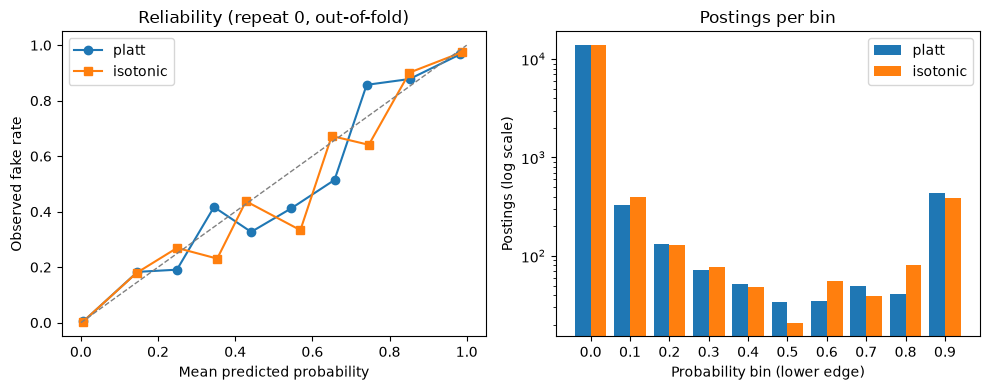

In [5]:
first_repeat = baseline.oof_scores[baseline.oof_scores["repeat"] == 0]
y_first = y_dev.loc[first_repeat.index]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
bins = np.linspace(0, 1, 11)
for method, marker in [("platt", "o"), ("isotonic", "s")]:
    probabilities = first_repeat[f"prob_{method}"]
    which = np.minimum(np.digitize(probabilities, bins) - 1, 9)
    table = pd.DataFrame({"p": probabilities, "y": y_first, "bin": which}).groupby("bin").agg(
        predicted=("p", "mean"), observed=("y", "mean"), postings=("y", "size"))
    axes[0].plot(table["predicted"], table["observed"], marker=marker, label=method)
    axes[1].bar(table.index + (0.2 if method == "isotonic" else -0.2), table["postings"], width=0.4, label=method)
axes[0].plot([0, 1], [0, 1], color="grey", linestyle="--", linewidth=1)
axes[0].set_xlabel("Mean predicted probability")
axes[0].set_ylabel("Observed fake rate")
axes[0].set_title("Reliability (repeat 0, out-of-fold)")
axes[0].legend()
axes[1].set_yscale("log")
axes[1].set_xticks(range(10), [f"{b:.1f}" for b in bins[:-1]])
axes[1].set_xlabel("Probability bin (lower edge)")
axes[1].set_ylabel("Postings (log scale)")
axes[1].set_title("Postings per bin")
axes[1].legend()
fig.tight_layout()
plt.show()

## Candidate 2: Sentence Embeddings

The 384 embedding columns are appended to the Step 2 feature matrix. They are L2-normalised like each TF-IDF block and passed through unscaled.

In [6]:
embedding_svm = run("embeddings", build_pipeline(STEP2_CONFIG.but(embeddings=True)))
embedding_table = judge(baseline, [embedding_svm])
embedding_table

embeddings: 687s


,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,passes rule
variant,,,,,,,,
embeddings,0.863 ± 0.049,-0.007,1/15,0.778 ± 0.059,-0.011,3/15,-0.014,False


## Candidate 3: LightGBM Stacking

Inside every training fold, `GroupedStacking` produces an out-of-fold score for each training posting from the Step 2 SVM (3-fold grouped inner CV), refits the SVM on the whole training fold, and fits LightGBM on the SVM score plus structured features. Categorical fields are ordinal-encoded inside the training fold and handled as categories by LightGBM; unseen categories are treated as missing.

**Fixed LightGBM settings:** 300 trees, learning rate 0.03, at most 15 leaves, at least 20 postings per leaf, 80% row and column subsampling, L2 penalty 1. No class weighting: only the ranking matters, because the threshold is chosen separately.

In [7]:
STACK_NUMERIC = list(BASE_BINARY + EXTRA_BINARY) + META_COLUMNS
STACK_CATEGORICAL = list(BASE_CATEGORICAL + EXTRA_CATEGORICAL)

def booster():
    return LGBMClassifier(
        n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
        random_state=42, n_jobs=1, verbose=-1,
    )

def stacking(text_config):
    return GroupedStacking(build_pipeline(text_config), booster(), STACK_NUMERIC, STACK_CATEGORICAL)

print(f"Structured features: {len(STACK_NUMERIC)} numeric, {len(STACK_CATEGORICAL)} categorical, plus the SVM score")
stacked = run("stacking", stacking(STEP2_CONFIG))
stacking_table = judge(baseline, [stacked])
stacking_table

Structured features: 19 numeric, 5 categorical, plus the SVM score


stacking: 2947s


,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,passes rule
variant,,,,,,,,
stacking,0.867 ± 0.050,-0.003,9/15,0.789 ± 0.051,-5.209e-04,8/15,-0.006,False


## Combination (only if both candidates pass)

In [8]:
passed = [r for r, table in [(embedding_svm, embedding_table), (stacked, stacking_table)]
          if table["passes rule"].iloc[0]]
print("Passed the rule:", [r.name for r in passed] or "none")

if len(passed) == 2:
    combined = run("stacking_embeddings", stacking(STEP2_CONFIG.but(embeddings=True)))
    better = max(passed, key=lambda r: r.folds["average_precision"].mean())
    display(judge(baseline, [combined]))
    vs_better = judge(better, [combined])
    print(f"Combination vs {better.name}:")
    display(vs_better)
    selected = combined if vs_better["passes rule"].iloc[0] else better
elif len(passed) == 1:
    selected = passed[0]
else:
    selected = baseline
print("Selected Step 3 model:", selected.name)

Passed the rule: none
Selected Step 3 model: step2_baseline


## Selected Model vs Step 2 Baseline

In [9]:
display(pd.concat([baseline.summary(), selected.summary()], axis=1).loc[["threshold"] + METRICS])
display(compare(baseline, selected, metrics=METRICS))

if selected is not baseline:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for ax, metric, label in zip(axes, ["average_precision", "f1"], ["PR-AUC", "F1 (nested threshold)"]):
        diff = selected.folds[metric].values - baseline.folds[metric].values
        ax.bar(range(1, len(diff) + 1), diff, color=["tab:green" if d > 0 else "tab:red" for d in diff])
        ax.axhline(0, color="black", linewidth=0.8)
        ax.axhline(diff.mean(), color="black", linestyle="--", linewidth=1, label=f"mean {diff.mean():+.3f}")
        ax.set_xlabel("Outer fold")
        ax.set_title(f"{label}: {selected.name} − Step 2 baseline")
        ax.legend()
        ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()

,step2_baseline,step2_baseline
threshold,-0.272 ± 0.070,-0.272 ± 0.070
average_precision,0.871 ± 0.047,0.871 ± 0.047
roc_auc,0.984 ± 0.007,0.984 ± 0.007
f1,0.789 ± 0.057,0.789 ± 0.057
precision,0.834 ± 0.065,0.834 ± 0.065
recall,0.752 ± 0.066,0.752 ± 0.066


,baseline,candidate,mean_diff,std_diff,folds_improved
metric,,,,,
average_precision,0.871,0.871,0.0,0.0,0/15
roc_auc,0.984,0.984,0.0,0.0,0/15
f1,0.789,0.789,0.0,0.0,0/15
precision,0.834,0.834,0.0,0.0,0/15
recall,0.752,0.752,0.0,0.0,0/15


## Overview

In [10]:
overview = judge(baseline, [results[n] for n in results if n != "step2_baseline"])
overview.to_csv(RESULTS_DIR / "step3_overview.csv")
overview

,PR-AUC,Δ PR-AUC,PR-AUC wins,F1,Δ F1,F1 wins,Δ recall,passes rule
variant,,,,,,,,
embeddings,0.863 ± 0.049,-0.007,1/15,0.778 ± 0.059,-1.103e-02,3/15,-0.014,False
stacking,0.867 ± 0.050,-0.003,9/15,0.789 ± 0.051,-5.209e-04,8/15,-0.006,False


## Findings

All numbers are mean ± std over the same 15 outer folds (seed 0) as Steps 1 and 2, paired against the Step 2 baseline (PR-AUC 0.871 ± 0.047, F1 0.789 ± 0.057).

**1. Calibration works and Platt scaling is kept.** Calibrators fitted on the inner out-of-fold scores give reliable probabilities on the outer test folds:

| | Brier score | ECE |
|---|---|---|
| Prior (training fake rate for every posting) | 0.046 ± 0.008 | – |
| Platt (sigmoid) | 0.014 ± 0.002 | 0.009 ± 0.003 |
| Isotonic | 0.014 ± 0.002 | 0.008 ± 0.003 |

Both methods reduce the Brier score by about 70% compared with the prior, and the average gap between predicted probability and observed fake rate is below one percentage point. Isotonic had the lower Brier score in only 1/15 folds, so the pre-set default, Platt scaling, is kept. Calibration does not change the ranking, so PR-AUC and F1 are unchanged; its value is that the model's output can now be read as a probability ("about 80% likely to be fake"), and a threshold can be stated as a probability instead of a raw SVM score.

**2. Sentence embeddings make the model slightly worse.** Adding the 384 `all-MiniLM-L6-v2` dimensions lowered PR-AUC by 0.007 (better in only 1/15 folds) and F1 by 0.011 (3/15). The rule is not passed. The word and character n-gram TF-IDF already captures the wording cues that separate fake postings; a general-purpose embedding of title and description (truncated at 256 word pieces) mainly describes *what the job is*, which is not what distinguishes fraud, and the extra dense dimensions dilute the sparse features.

**3. LightGBM stacking brings no gain.** Stacking the out-of-fold SVM score with 24 structured features gave PR-AUC 0.867 ± 0.050 (−0.003, better in 9/15 folds) and F1 0.789 (unchanged, 8/15). The rule is not passed. The structured signals (company logo, empty company profile, contact tokens) are either already in the SVM or, as Step 2 showed, already reflected in the text features, so the booster has little left to add. A quick check on the single original validation split before this run had suggested a large gain (average precision 0.867 → 0.894); under repeated grouped CV the gain disappeared. This is exactly the kind of single-split result the Step 1 protocol was designed to catch.

**4. No combination was run**, because neither candidate passed (as fixed before running).

**Selected model after Step 3:** the Step 2 SVM (`STEP2_CONFIG`) with Platt calibration on top. The "Selected Model vs Step 2 Baseline" table above therefore compares the baseline with itself.

**Cost.** The embedding model adds about 11 minutes of one-off computation; the stacking model trains about three times slower than the SVM alone (49 minutes for the full CV instead of 18). Neither cost is justified by the results.

**Next step.** Step 4 (DistilBERT fine-tuning) is optional and needs a GPU; given that a general-purpose sentence embedding did not help, a large gain is not expected. Step 5 evaluates the selected model once on the held-out test set.